In [1]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "data" / "fashion_mnist"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

for directory in [DATASET_DIR, CHECKPOINT_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

GENERAL_CONFIG = CONFIG["general"]
AE_CONFIG = CONFIG["models"]["vanilla_ae"]


RANDOM_SEED = GENERAL_CONFIG["random_seed"]

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

if GENERAL_CONFIG["device"] == "auto":
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
else:
    device = torch.device(GENERAL_CONFIG["device"])

print("Project Directory:", PROJECT_DIR)
print("Model:", "Vanilla Autoencoder")
print("Available Device:", device)
print("Random Seed:", RANDOM_SEED)
print("Latent Dimension:", AE_CONFIG["latent_dim"])

Project Directory: d:\generative-models-comparison
Model: Vanilla Autoencoder
Available Device: cpu
Random Seed: 42
Latent Dimension: 64


In [3]:
dataset_path = DATASET_DIR / "fashion_mnist_splits.pt"

dataset = torch.load(
    dataset_path,
    map_location="cpu",
    weights_only=True
)

train_images = dataset["train_images"]
val_images = dataset["val_images"]
test_images = dataset["test_images"]

print("Training Images:", train_images.shape)
print("Validation Images:", val_images.shape)
print("Testing Images:", test_images.shape)

Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])


Preprocessing

In [4]:
# Normalize Images
train_images = train_images.float() / 255.0
val_images = val_images.float() / 255.0
test_images = test_images.float() / 255.0

# Flatten Images
train_images = train_images.view(-1, 784)
val_images = val_images.view(-1, 784)
test_images = test_images.view(-1, 784)

# Display Dataset Information
print("Training Shape:", train_images.shape)
print("Validation Shape:", val_images.shape)
print("Testing Shape:", test_images.shape)

print("\nPixel Value Range:")
print("Minimum:", train_images.min().item())
print("Maximum:", train_images.max().item())

Training Shape: torch.Size([56000, 784])
Validation Shape: torch.Size([7000, 784])
Testing Shape: torch.Size([7000, 784])

Pixel Value Range:
Minimum: 0.0
Maximum: 1.0


In [5]:
# Create TensorDatasets
train_dataset = TensorDataset(train_images, train_images)
val_dataset = TensorDataset(val_images, val_images)
test_dataset = TensorDataset(test_images, test_images)

# Create DataLoaders
BATCH_SIZE = GENERAL_CONFIG["batch_size"]

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch Size:", BATCH_SIZE)
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Batch Size: 128
Training Batches: 438
Validation Batches: 55
Testing Batches: 55


In [6]:
class VanillaAutoencoder(nn.Module):
    def __init__(self, config):
        super(VanillaAutoencoder, self).__init__()

        encoder_layers = []
        encoder_dims = config["encoder"]

        # Build Encoder
        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(
                nn.Linear(encoder_dims[i], encoder_dims[i + 1])
            )

            if i < len(encoder_dims) - 2:
                encoder_layers.append(nn.ReLU())

        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        decoder_dims = config["decoder"]

        # Build Decoder
        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(
                nn.Linear(decoder_dims[i], decoder_dims[i + 1])
            )

            if i < len(decoder_dims) - 2:
                decoder_layers.append(nn.ReLU())
            else:
                decoder_layers.append(nn.Sigmoid())

        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)

        return reconstructed, latent


# Initialize Model
model = VanillaAutoencoder(AE_CONFIG).to(device)

print(model)

VanillaAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [7]:
# Define Loss Function
criterion = nn.MSELoss()

# Define Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=AE_CONFIG["learning_rate"]
)

# Training Configuration
EPOCHS = AE_CONFIG["epochs"]

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Learning Rate:", AE_CONFIG["learning_rate"])
print("Epochs:", EPOCHS)

Loss Function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning Rate: 0.001
Epochs: 50


In [8]:
train_losses = []
val_losses = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    # Training 
    model.train()
    running_train_loss = 0.0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        reconstructed, latent = model(images)
        loss = criterion(reconstructed, targets)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # Validation 
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            reconstructed, latent = model(images)
            loss = criterion(reconstructed, targets)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_losses.append(epoch_val_loss)

    # Best Model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss

        torch.save(
            model.state_dict(),
            CHECKPOINT_DIR / "vanilla_ae.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

print("\nTraining Completed!")
print(f"Best Validation Loss: {best_val_loss:.6f}")

Epoch [1/50] Train Loss: 0.035141 Val Loss: 0.021465
Epoch [2/50] Train Loss: 0.018983 Val Loss: 0.017501
Epoch [3/50] Train Loss: 0.016173 Val Loss: 0.015278
Epoch [4/50] Train Loss: 0.014511 Val Loss: 0.013890
Epoch [5/50] Train Loss: 0.013296 Val Loss: 0.012888
Epoch [6/50] Train Loss: 0.012301 Val Loss: 0.012017
Epoch [7/50] Train Loss: 0.011583 Val Loss: 0.011378
Epoch [8/50] Train Loss: 0.011028 Val Loss: 0.010954
Epoch [9/50] Train Loss: 0.010572 Val Loss: 0.010538
Epoch [10/50] Train Loss: 0.010167 Val Loss: 0.010100
Epoch [11/50] Train Loss: 0.009782 Val Loss: 0.009756
Epoch [12/50] Train Loss: 0.009488 Val Loss: 0.009767
Epoch [13/50] Train Loss: 0.009171 Val Loss: 0.009260
Epoch [14/50] Train Loss: 0.008919 Val Loss: 0.009200
Epoch [15/50] Train Loss: 0.008682 Val Loss: 0.008949
Epoch [16/50] Train Loss: 0.008464 Val Loss: 0.008663
Epoch [17/50] Train Loss: 0.008282 Val Loss: 0.008436
Epoch [18/50] Train Loss: 0.008125 Val Loss: 0.008477
Epoch [19/50] Train Loss: 0.007949 Va

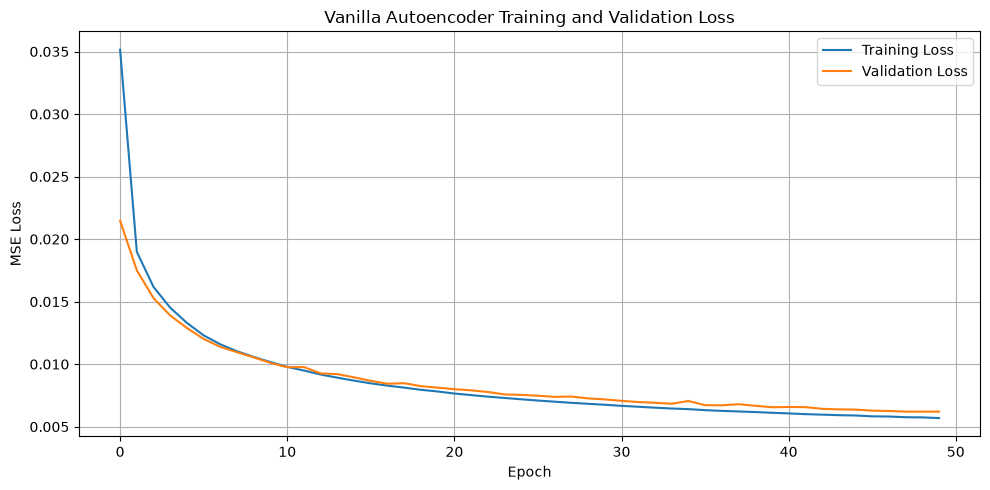

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Vanilla Autoencoder Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vanilla_ae_training_curves.png",
    dpi=100
)

plt.show()

In [11]:
# Load Best Model
model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "vanilla_ae.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

VanillaAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

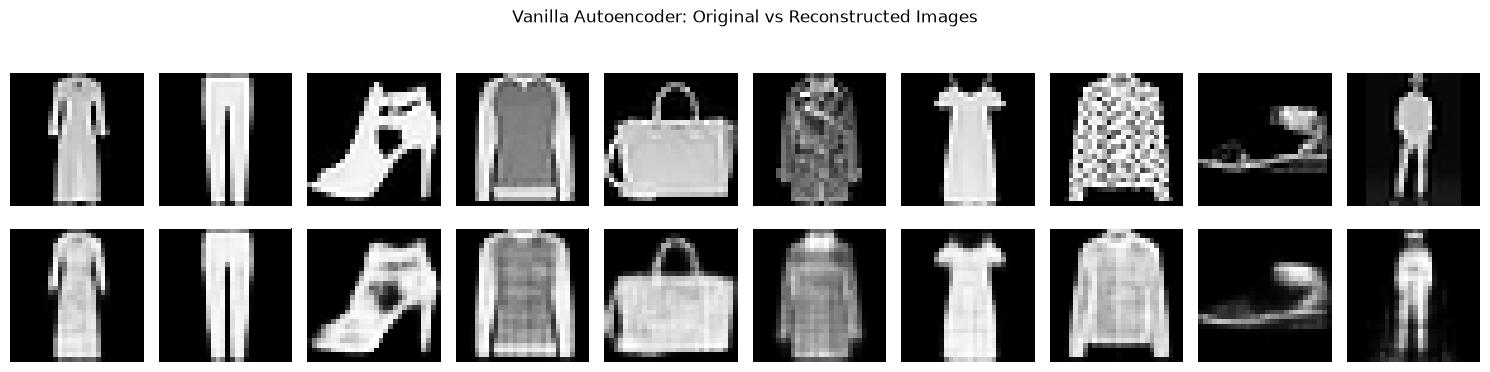

In [12]:
# Get Test Samples
images, targets = next(iter(test_loader))
images = images[:10].to(device)

# Generate Reconstructions
model.eval()

with torch.no_grad():
    reconstructed, latent = model(images)

# Convert to NumPy
original_images = images.cpu().view(-1, 28, 28).numpy()
reconstructed_images = reconstructed.cpu().view(-1, 28, 28).numpy()

# Visualize Results
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):
    # Original Images
    axes[0, i].imshow(original_images[i], cmap="gray")
    axes[0, i].axis("off")

    # Reconstructed Images
    axes[1, i].imshow(reconstructed_images[i], cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Reconstructed", fontsize=10)

plt.suptitle("Vanilla Autoencoder: Original vs Reconstructed Images")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vanilla_ae_reconstructions.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()